# L5 — Is the plot short of rain? Choosing the rain data behind `water_stress`

*Krops weather notebooks · 1 of 2 · [2 — L8 spreading window](02_L8_spreading_window.ipynb) · design: [Krops L5 & L8 — Weather Data Design](https://claude.ai/code/artifact/1c498342-d6cd-48a9-bd7f-7da06669b02a)*

## Problem statement

Krops reads palm crowns from drone images (L1) and turns weak crowns into a fertiliser recipe (L6). A palm short of water can look like a palm short of nutrients, so a dry month could send fertiliser to palms that can't use it.

The proposal (17 Sep 2026) guards against this with *"hujan < 60 mm/bln → tunda"*. On 9 Oct we decided what that means: a **water-stress check on the rain that actually fell in the last 30 days (P30)**, not on the long-term average, because it's recent weather that can mimic a deficiency. When P30 is under 60 mm, `water_stress` is set and L6 lowers its confidence instead of stopping the recipe.

**The problem:** which rain data can tell Krops, reliably and cheaply, whether the Tanjung Pinang plot has had less than 60 mm in the last 30 days? It has to be fetched at sync and cached for offline use, and we need to know when *not* to trust it.

## Thinking flow

1. Which providers could give us P30?
2. What does NASA POWER actually give us for this point?
3. Can we trust the numbers?
4. Do two independent sources agree on P30 and the flag?
5. How often would the flag fire at this site?
6. Which source matches real rain?
7. Putting it together: the P30 pipeline L5 should run

### 1. Which providers could give us P30?

We needed daily rain for the last 30 days at one point in Riau, free or close to it, that an app can fetch at sync and cache. The MVP is an iPhone, so WeatherKit came first.

| Provider | What it offers for P30 | Why it stayed or went |
| --- | --- | --- |
| **Apple WeatherKit** | `dailySummary`: daily rain for the past 30 days | Swift-only on iOS 18+, and Apple lists no Indonesian data sources |
| **NASA POWER** | Daily `PRECTOTCORR` since 1981, free REST API | **Chosen for L5** (9 Oct): free, no key, works from any device, same request as the irradiance log |
| **BMKG public API** | A forecast for about the next 3 days | Horizon too short, and no history at all, so it can't give P30 |
| **Open-Meteo** | Forecasts and an ERA5-based history API | Not evaluated at the time (see below) |
| **BMKG station data** (Data Online) | Measured daily rain at Tanjung Pinang airport | Manual download; validation only |
| **Rain gauge at the plot** | Measured daily rain at the palms | Validation only (planned for Dumai; the trial is now at Tanjung Pinang) |

**Open-Meteo.** Its [historical API](https://open-meteo.com/en/docs/historical-weather-api) offers ERA5 (0.25°, about 25 km) and ERA5-Land (0.1°) back to 1940/1950 with about a 5-day delay, a finer grid than NASA POWER's. But the [free API is for non-commercial use only](https://open-meteo.com/en/pricing); Krops is a paid service, so production use needs a paid plan. In this notebook it is off by default (`USE_OPEN_METEO=1` in `.env` turns it on for a one-off comparison, if the team is comfortable that counts as non-commercial research).

**WeatherKit history over REST.** The design doc lists `dailySummary` (Swift, iOS 18) as WeatherKit's only history, but the REST API returns past days too: `forecastDaily` with `dailyStart`/`dailyEnd` in the past goes back to 1 Aug 2021. That gives a second P30 source on any device, and it is what this notebook compares NASA POWER against. These are values from Apple's models, not measurements.

In [1]:
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import krops_weather as kw
from krops_weather import LAT, LON, P30_THRESHOLD_MM, SITE_NAME, SUSPECT_RATIO, TODAY, WK_READY

kw.use_chart_style()
print(f"{SITE_NAME}: {LAT}, {LON} · today {TODAY} · WeatherKit credentials: {'yes' if WK_READY else 'no (WeatherKit cells skip)'}")

Tanjung Pinang: 0.92, 104.45 · today 2026-10-11 · WeatherKit credentials: yes


### 2. What does NASA POWER actually give us for this point?

**Why we ask.** We picked NASA POWER for being free and easy to reach. Before building on it we should know three things: how far behind today its data runs (P30 can't end today), what it is made from, and what area one value stands for.

The request asks for rain (`PRECTOTCORR`, mm/day) and the two irradiance values the design logs (`ALLSKY_SFC_SW_DWN`, `CLRSKY_SFC_SW_DWN`) from 1 January this year. Responses are saved to `data/raw/` and reused on the same day.

In [2]:
this_year, units, sources = kw.fetch_nasa_power(min(date(TODAY.year, 1, 1), TODAY - timedelta(days=120)), TODAY)
nasa_recent = this_year["PRECTOTCORR"].dropna()

rain_end = nasa_recent.index.max()
sun_end = this_year["ALLSKY_SFC_SW_DWN"].dropna().index.max()
print("Made from:", sources)
print("Units:", units)
print(f"Last day with rain: {rain_end} ({(TODAY - rain_end).days} days behind) · last day with irradiance: {sun_end} ({(TODAY - sun_end).days} days behind)")

s, n, w, e = kw.merra2_cell(LAT, LON)
print(f"Rain grid cell: lat {s:.2f}–{n:.2f}, lon {w:.4f}–{e:.4f} (about 55 × 70 km)")
print(f"Map: https://www.openstreetmap.org/?minlon={w}&minlat={s}&maxlon={e}&maxlat={n}&box=yes")
this_year.tail(6)

Made from: ['GEOSIT', 'MERRA2', 'FLASHFLUX', 'SYN1DEG']
Units: {'PRECTOTCORR': 'mm/day', 'ALLSKY_SFC_SW_DWN': 'MJ/m^2/day', 'CLRSKY_SFC_SW_DWN': 'MJ/m^2/day'}
Last day with rain: 2026-10-08 (3 days behind) · last day with irradiance: 2026-10-06 (5 days behind)
Rain grid cell: lat 0.75–1.25, lon 104.0625–104.6875 (about 55 × 70 km)
Map: https://www.openstreetmap.org/?minlon=104.0625&minlat=0.75&maxlon=104.6875&maxlat=1.25&box=yes


,PRECTOTCORR,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN
2026-10-06,0.20,22.43,NaN
2026-10-07,1.43,NaN,NaN
2026-10-08,0.63,NaN,NaN
2026-10-09,NaN,NaN,NaN
2026-10-10,NaN,NaN,NaN
2026-10-11,NaN,NaN,NaN


**What we found** *(run on 11 Oct 2026)*

- **Delay.** Rain runs **3 days** behind (last day 8 Oct) and irradiance 5 days. The clear-sky irradiance column is empty for recent months. So P30 can never end on the sync day; the design's "fetch about the last 40 days" already allows for this.
- **What it is made from.** This year's values come from **GEOS-IT** and **MERRA-2** (two NASA weather models) plus satellite products for sunlight. Nothing in it is a rain gauge at the site.
- **What one value covers.** The rain cell runs from 0.75° to 1.25° N and 104.06° to 104.69° E: Tanjung Pinang, the western half of Bintan, and a lot of sea (open the map link).

**One value for 55 × 70 km, much of it sea.** The design notes that a cell covers the plot and its neighbours. What it didn't weigh is that rain over the sea is averaged in. A storm that hits one corner of the cell becomes light rain everywhere in it. Expect more drizzle days and smaller peaks than a gauge would record at the plot.

### 3. Can we trust the numbers?

**Why we ask.** NASA POWER rain is model output (a reanalysis), not a measurement. It can be wrong without any warning in the response, and P30 inherits every error. We need a check that runs *before* L5 uses a value.

**What we compare against.** Two references, each independent of the month being checked:

- **NASA POWER's own 1991–2020 normals**: the median rain for each calendar month over the standard 30-year climate period. Rain varies a lot from year to year, but a month several times its normal is rare.
- **WeatherKit's past daily values** for the same days: Apple's models, built separately from NASA's.

First the long view, year by year.

NASA POWER history made from: ['MERRA2']
1991–2020 average: 2413 mm/year


,NASA POWER (mm),WeatherKit (mm),NASA ÷ WeatherKit
2016,2247.0,NaN,NaN
2017,2354.0,NaN,NaN
2018,2072.0,NaN,NaN
2019,1725.0,NaN,NaN
2020,2406.0,NaN,NaN
2021,3512.0,NaN,NaN
2022,3380.0,2836.0,1.19
2023,4077.0,2798.0,1.46
2024,3629.0,2719.0,1.33
2025,5717.0,2870.0,1.99


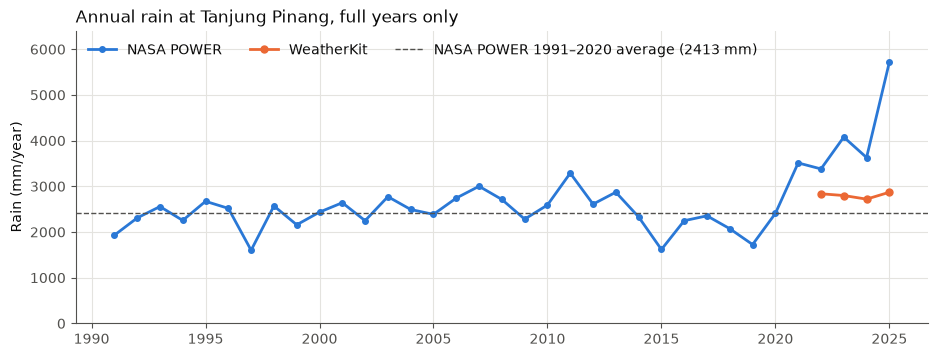

In [3]:
history, _, history_sources = kw.fetch_nasa_power(date(1991, 1, 1), date(2025, 12, 31), params=("PRECTOTCORR",))
nasa_all = pd.concat([history["PRECTOTCORR"], nasa_recent]).dropna()
nasa_all = nasa_all[~nasa_all.index.duplicated(keep="last")].sort_index()

normal_period = nasa_all[(nasa_all.index >= date(1991, 1, 1)) & (nasa_all.index <= date(2020, 12, 31))]
normals = kw.monthly_normals(nasa_all)  # median mm per calendar month, 1991–2020

wk_rain = None
if WK_READY:
    # Past days are cached for good, so only the last month or so is fetched again on later runs
    wk_rain = kw.fetch_weatherkit_history(date(2021, 8, 1), nasa_recent.index.max())["rain_mm"]


def full_years(rain, first, last):
    yearly = rain.groupby(pd.to_datetime(rain.index).year)
    totals, days = yearly.sum(), yearly.size()
    return totals[(days >= 360) & (totals.index >= first) & (totals.index <= last)]  # allow a few missing days


annual = pd.DataFrame({"NASA POWER (mm)": full_years(nasa_all, 1991, 2025)})
if wk_rain is not None:
    annual["WeatherKit (mm)"] = full_years(wk_rain, 2022, 2025)
    annual["NASA ÷ WeatherKit"] = annual["NASA POWER (mm)"] / annual["WeatherKit (mm)"]
normal_mean = annual.loc[1991:2020, "NASA POWER (mm)"].mean()

print("NASA POWER history made from:", history_sources)
print(f"1991–2020 average: {normal_mean:.0f} mm/year")
display(annual.loc[2016:].round({"NASA POWER (mm)": 0, "WeatherKit (mm)": 0, "NASA ÷ WeatherKit": 2}))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(annual.index, annual["NASA POWER (mm)"], color=kw.NASA_COLOR, linewidth=2, marker="o", markersize=4, label="NASA POWER")
if wk_rain is not None:
    wk_years = annual["WeatherKit (mm)"].dropna()
    ax.plot(wk_years.index, wk_years, color=kw.WK_COLOR, linewidth=2, marker="o", markersize=5, label="WeatherKit")
ax.axhline(normal_mean, color=kw.MUTED, linestyle="--", linewidth=1, label=f"NASA POWER 1991–2020 average ({normal_mean:.0f} mm)")
ax.set_ylim(0, annual[["NASA POWER (mm)"]].max().max() * 1.12)
ax.set_ylabel("Rain (mm/year)")
ax.set_title(f"Annual rain at {SITE_NAME}, full years only", loc="left")
ax.legend(loc="upper left", ncol=3)
plt.show()

**What we found** *(run on 11 Oct 2026)*

- From 1991 to 2020 NASA POWER gives this point **2,413 mm a year** on average, with dry years down to about 1,600 mm and wet years up to about 3,300 mm.
- From **2021 it climbs out of that range**: 3,512, 3,380, 4,077, 3,629, and **5,717 mm in 2025**. The 2025 total is more than twice the long-term average.
- WeatherKit gives **2,719–2,870 mm** for each full year from 2022 to 2025: steady, and close to NASA POWER's own long-term average. NASA POWER is 1.19× WeatherKit in 2022, rising to **1.99×** in 2025.
- The history comes from **MERRA-2 alone**, so this drift is not just the GEOS-IT model that 2026 uses.

Both sources can't be right. WeatherKit staying near the 30-year average while NASA POWER doubles points to NASA POWER's recent years being too wet. A short run of wetter years (2021–22 were La Niña years) is plausible; a steady climb to twice the normal is not.

**NASA POWER's history isn't uniformly reliable.** The design treats NASA POWER as one consistent record since 1981. At this point it is consistent up to about 2020 and inflated after. That matters here (P30 reads too high, which hides dry spells) and even more for L8's month tables, which average these years (see notebook 2).

A drift over years is one problem; a month that is plainly broken is another, and that one we can catch automatically. A month is marked **suspect** when NASA POWER is more than `SUSPECT_RATIO` (3×) its 1991–2020 normal **and**, where WeatherKit exists, more than 3× WeatherKit too. Requiring both keeps a genuinely very wet month (which WeatherKit would also show) from being thrown out. Suspect months are left out of everything after this point.

In [4]:
import inspect

print(inspect.getsource(kw.suspect_months))  # the check lives in krops_weather.py because notebook 2 uses it too

check = kw.suspect_months(nasa_all[nasa_all.index >= date(2021, 8, 1)], normals, wk_rain)
bad = check.index[check["suspect"]]
nasa_ok = kw.drop_months(nasa_all, bad)

print(f"Suspect months since Aug 2021: {len(bad)} — {', '.join(str(m) for m in bad) or 'none'}")
display(check[check.index >= pd.Period(TODAY, "M") - 12])

def suspect_months(nasa, normals, wk=None, ratio=SUSPECT_RATIO):
    """Months where NASA POWER is over `ratio` × its normal AND over `ratio` × WeatherKit (where WeatherKit exists)."""
    months = monthly_mm(nasa)
    check = pd.DataFrame({
        "days": nasa.groupby(pd.PeriodIndex(pd.to_datetime(nasa.index), freq="M")).size(),
        "NASA POWER (mm)": months,
        "1991–2020 normal (mm)": [normals[m.month] for m in months.index],
    })
    too_high = check["NASA POWER (mm)"] > ratio * check["1991–2020 normal (mm)"]
    if wk is not None:
        check["WeatherKit (mm)"] = monthly_mm(wk)
        too_high &= ~(check["NASA POWER (mm)"] <= ratio * check["WeatherKit (mm)"])  # no WeatherKit month → the normal alone decides
    check["suspect"] = too_high
    return check.round(0)

Suspect months since Aug 2021: 11 — 2024-02, 2024-03, 2025-12, 2026-01, 2026-02, 2026-03, 2026-04, 2026-05, 2026-06, 2026-07, 2026-08


,days,NASA POWER (mm),1991–2020 normal (mm),WeatherKit (mm),suspect
2025-10,31,597.0,211.0,132.0,False
2025-11,30,277.0,290.0,327.0,False
2025-12,31,1239.0,311.0,299.0,True
2026-01,31,2455.0,182.0,35.0,True
2026-02,28,1743.0,94.0,123.0,True
2026-03,31,2450.0,154.0,35.0,True
2026-04,30,1819.0,205.0,198.0,True
2026-05,31,2328.0,210.0,290.0,True
2026-06,30,2651.0,161.0,187.0,True
2026-07,31,2330.0,184.0,149.0,True


**What we found** *(run on 11 Oct 2026)*

- **11 suspect months** since Aug 2021: Feb and Mar 2024, Dec 2025, and **every month from Jan to Aug 2026**. In 2026 NASA POWER gives 1,409–2,651 mm a month, where the normals are 94–210 mm and WeatherKit 35–290 mm.
- Sep and Oct 2026 are back to normal levels (95 and 22 mm so far) and are kept. That's why today's P30 can still use NASA POWER.
- **What the check misses:** milder inflation. Oct 2025 (597 mm) is 4.5× WeatherKit but only 2.8× its normal, so it is kept. The check stops the worst errors, not the slow drift seen above.

### 4. Do two independent sources agree on P30 and the flag?

**Why we ask.** L5 doesn't need every day right; it needs the 30-day total on the right side of 60 mm. If NASA POWER (trusted months only) and WeatherKit set the same flag on almost every day, the source choice barely matters for L5. The days they disagree show where it does.

**How P30 is computed.** The 30 calendar days ending on the latest day with data, all 30 present. A gap (a missing or suspect day) means no P30 for that window, rather than quietly summing fewer days. The rolling version repeats this for every day since Aug 2021, as if L5 had run on each of them.

,p30_mm,p30_start_date,p30_end_date,p30_source,water_stress
0,113.2,2026-09-09,2026-10-08,NASA POWER,False
1,110.8,2026-09-09,2026-10-08,WeatherKit,False


,value
days compared,1444.0
"median P30, NASA POWER (mm)",297.0
"median P30, WeatherKit (mm)",214.0
"median gap, NASA − WeatherKit (mm)",71.0
flag raised by both (days),0.0
only NASA POWER (days),0.0
only WeatherKit (days),15.0


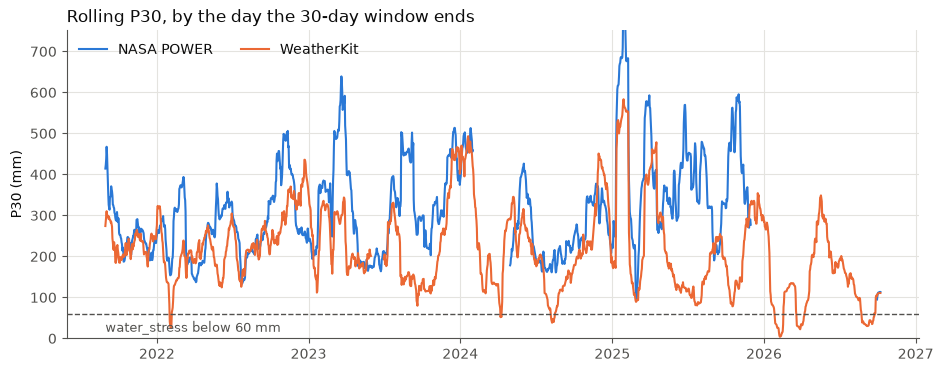

WeatherKit flags water stress on days where NASA POWER failed the check:


,days flagged,median WeatherKit P30 (mm),median unchecked NASA POWER P30 (mm)
2024-04,3,52.0,412.0
2026-01,5,36.0,2349.0
2026-02,16,14.0,2187.0
2026-03,12,29.0,2121.0
2026-04,8,37.0,2452.0
2026-08,8,40.0,1551.0
2026-09,24,38.0,822.0


In [5]:
def compute_p30(rain, source):
    rain = rain.dropna().sort_index()
    if rain.empty:
        return None
    end = rain.index.max()
    window = rain[rain.index > end - timedelta(days=30)]
    if len(window) < 30:
        return None
    p30_mm = round(float(window.sum()), 1)
    return {
        "p30_mm": p30_mm,
        "p30_start_date": window.index[0],
        "p30_end_date": end,
        "p30_source": source,
        "water_stress": p30_mm < P30_THRESHOLD_MM,
    }


def rolling_p30(rain):
    rain = rain.dropna()
    rain.index = pd.to_datetime(rain.index)
    return rain.rolling("30D", min_periods=30).sum()  # only full 30-day windows


p30_sources = {"NASA POWER": nasa_ok}
if wk_rain is not None:
    p30_sources["WeatherKit"] = wk_rain
if kw.USE_OPEN_METEO:
    p30_sources["Open-Meteo (ERA5)"] = kw.fetch_open_meteo_archive(date(2021, 8, 1), nasa_recent.index.max())

display(pd.DataFrame([r for r in (compute_p30(rain, name) for name, rain in p30_sources.items()) if r]))

if wk_rain is not None:
    p30 = pd.concat({name: rolling_p30(rain) for name, rain in p30_sources.items()}, axis=1, sort=True).dropna()
    flag = p30 < P30_THRESHOLD_MM
    gap = (p30["NASA POWER"] - p30["WeatherKit"])
    display(pd.Series({
        "days compared": len(p30),
        "median P30, NASA POWER (mm)": round(p30["NASA POWER"].median(), 0),
        "median P30, WeatherKit (mm)": round(p30["WeatherKit"].median(), 0),
        "median gap, NASA − WeatherKit (mm)": round(gap.median(), 0),
        "flag raised by both (days)": int((flag["NASA POWER"] & flag["WeatherKit"]).sum()),
        "only NASA POWER (days)": int((flag["NASA POWER"] & ~flag["WeatherKit"]).sum()),
        "only WeatherKit (days)": int((~flag["NASA POWER"] & flag["WeatherKit"]).sum()),
    }, name="value").to_frame())

    colors = {"NASA POWER": kw.NASA_COLOR, "WeatherKit": kw.WK_COLOR, "Open-Meteo (ERA5)": kw.THIRD_COLOR}
    fig, ax = plt.subplots(figsize=(11, 4))
    for name in p30.columns:
        full = rolling_p30(p30_sources[name])  # gaps (suspect months) show as breaks in the line
        full = full.reindex(pd.date_range(p30.index.min(), p30.index.max()))
        ax.plot(full.index, full, color=colors[name], linewidth=1.5, label=name)
    ax.axhline(P30_THRESHOLD_MM, color=kw.MUTED, linestyle="--", linewidth=1)
    ax.annotate(f"water_stress below {P30_THRESHOLD_MM} mm", (p30.index[0], P30_THRESHOLD_MM),
                xytext=(0, -13), textcoords="offset points", color=kw.MUTED, fontsize=9)
    ax.set_ylim(0, p30.quantile(0.99).max() * 1.1)
    ax.set_ylabel("P30 (mm)")
    ax.set_title("Rolling P30, by the day the 30-day window ends", loc="left")
    ax.legend(loc="upper left", ncol=len(p30.columns))
    plt.show()

    # Days WeatherKit says were dry while NASA POWER has no trusted value: what would an unchecked NASA POWER have said?
    dry = pd.concat({"WeatherKit P30": rolling_p30(wk_rain), "NASA POWER P30, unchecked": rolling_p30(nasa_all)}, axis=1, sort=True).dropna()
    dry = dry[(dry["WeatherKit P30"] < P30_THRESHOLD_MM) & ~dry.index.isin(p30.index)]
    if len(dry):
        print("WeatherKit flags water stress on days where NASA POWER failed the check:")
        by_month = dry.groupby(dry.index.to_period("M"))
        display(pd.DataFrame({"days flagged": by_month.size(), "median WeatherKit P30 (mm)": by_month["WeatherKit P30"].median().round(0),
                              "median unchecked NASA POWER P30 (mm)": by_month["NASA POWER P30, unchecked"].median().round(0)}))
else:
    print("Skipped the comparison: no WeatherKit credentials")

**What we found** *(run on 11 Oct 2026)*

- **Today they agree:** P30 for 9 Sep – 8 Oct is **113.2 mm** from NASA POWER and **110.8 mm** from WeatherKit. Neither flags water stress.
- **Over four years** (1,444 days where both have a full 30-day window), the two rise and fall together, but NASA POWER sits higher: median P30 **297 vs 214 mm**, a typical gap of **71 mm**, which is more than the 60 mm threshold itself. NASA POWER never raised the flag on those days; WeatherKit raised it on 15.
- **The days that matter most** are the ones NASA POWER failed. On **76 days** (Jan–Apr 2026, Aug–Sep 2026, and three days in Apr 2024) WeatherKit puts P30 under the threshold (monthly medians 14–52 mm). On the same days an *unchecked* NASA POWER P30 reads **412–2,452 mm** (monthly medians).

Without the step 3 check, L5 would have reported "no water stress" right through the two driest spells WeatherKit shows in 2026. We can't yet say WeatherKit's dry spells were real; that is step 6's job. But NASA POWER's numbers for those months are impossible either way.

**The pattern to remember:** every NASA POWER error we found runs *wet*. For L5 that is the dangerous direction: too much rain hides drought, and drought is the thing L5 exists to catch.

### 5. How often would the flag fire at this site?

**Why we ask.** The 60 mm threshold came with the proposal, which was written for Riau in general. Bintan is wet for most of the year. If P30 almost never drops below 60 mm here, L5's rain rule will rarely change a recipe; if it drops often in one season, that season is when L5 matters and when the source choice matters most.

**What we did.** For every day in the normal period (1991–2020, NASA POWER before any drift) and in WeatherKit's full years (2022–2025), compute P30 and count the share of days below 60 mm, by calendar month.

NASA POWER 1991–2020: P30 below 60 mm on 6% of days
WeatherKit 2022–2025: P30 below 60 mm on 1% of days


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
NASA POWER 1991–2020,4.0,19.0,18.0,1.0,0.0,1.0,3.0,10.0,10.0,4.0,0.0,0.0
WeatherKit 2022–2025,0.0,4.0,0.0,2.0,0.0,0.0,0.0,8.0,0.0,0.0,0.0,0.0


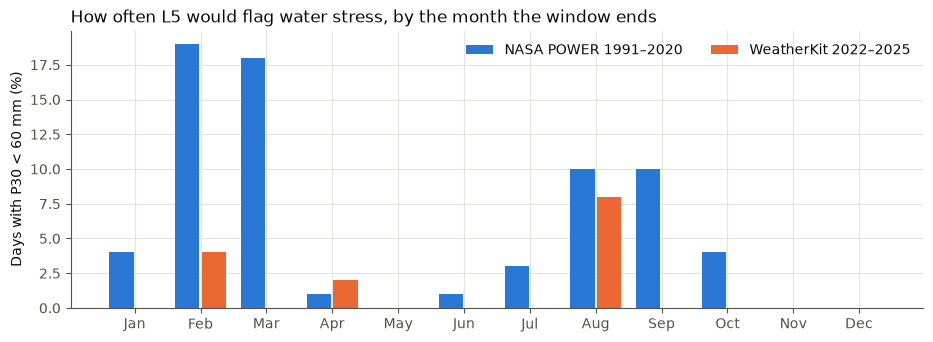

In [6]:
def share_flagged(rain):
    p = rolling_p30(rain).dropna()
    return (p < P30_THRESHOLD_MM).groupby(p.index.month).mean() * 100


periods = {"NASA POWER 1991–2020": normal_period}
if wk_rain is not None:
    periods["WeatherKit 2022–2025"] = wk_rain[(wk_rain.index >= date(2022, 1, 1)) & (wk_rain.index <= date(2025, 12, 31))]

shares = pd.DataFrame({name: share_flagged(rain) for name, rain in periods.items()}).round(0)
shares.index = pd.to_datetime(shares.index, format="%m").strftime("%b")
for name, rain in periods.items():
    print(f"{name}: P30 below 60 mm on {(rolling_p30(rain).dropna() < P30_THRESHOLD_MM).mean():.0%} of days")
display(shares.T)

fig, ax = plt.subplots(figsize=(11, 3.6))
width = 0.8 / len(shares.columns)
colors = [kw.NASA_COLOR, kw.WK_COLOR]
for i, col in enumerate(shares.columns):
    ax.bar([x + (i - (len(shares.columns) - 1) / 2) * width for x in range(12)], shares[col], width=width * 0.92,
           color=colors[i], label=col)
ax.set_xticks(range(12), shares.index)
ax.set_ylabel("Days with P30 < 60 mm (%)")
ax.set_title("How often L5 would flag water stress, by the month the window ends", loc="left")
ax.legend(loc="upper right", ncol=2)
plt.show()

**What we found** *(run on 11 Oct 2026)*

- In the normal period, P30 falls below 60 mm on **6% of days**. It is concentrated in **February (19%) and March (18%)**, with a smaller dry season in **August–September (10%)**, and it never happens in November–December.
- WeatherKit's four full years show the same seasons, but less often: **1% of days** overall (Feb 4%, Aug 8%). Four years is a short sample, and 2022–2025 may simply have been wet years.

So at Tanjung Pinang, L5's rain rule is mostly quiet. It matters when a scan falls in **Feb–Mar or Aug–Sep**, and those are exactly the months where a source that runs wet (step 4) would hide it.

**When the rule matters.** The 60 mm threshold came from the proposal for Riau in general. At this site it fires rarely and seasonally, so the scan calendar decides how much L5's rain check is worth. A scan planned for March should expect it to matter.

### 6. Which source matches real rain?

**Why we ask.** Steps 3 and 4 compare two models with each other. Agreement makes an error less likely, but two models can share a mistake, and the 60 mm line is only meaningful in real rain. A measurement settles it.

**What counts as a measurement here.**

| Reference | File | Notes |
| --- | --- | --- |
| BMKG station, Tanjung Pinang airport | `data/bmkg.xlsx` (export from [BMKG Data Online](https://dataonline.bmkg.go.id), daily **RR**) | A few km from the plot. For a 30-day total that distance matters little |
| Rain gauge at the trial plot | `data/gauge.csv` (`date,rain_mm`, 0 on dry days) | The plot itself. Read at 07:00, filed under the previous day |

The loader in `krops_weather.py` reads a BMKG export as downloaded: it finds the `Tanggal`/`RR` header below the station details, reads `dd-mm-yyyy` dates, and converts **8888** (too little to measure) to 0 and **9999** (no data) to missing. It then checks which date shift lines BMKG up best with the models (−1 means BMKG files each 07:00 reading under the morning it was read; set `BMKG_SHIFT_DAYS=-1` in `.env` if so).

**NOAA's copy of the station.** NOAA republishes daily summaries for the same airport station (WMO 96091, "KIJANG"), free and without login, up to Aug 2025. We tried it: only 3–14 days a year carry a complete 24-hour rain report; most days are built from one to three of the four 6-hourly reports, so the daily totals undercount. It can't stand in for BMKG's own data.

In [7]:
refs = kw.load_references()
if refs:
    for name, ref in refs.items():
        print(f"{name}: {len(ref)} days, {ref.index.min()} to {ref.index.max()}")
    if "BMKG station" in refs:
        print(f"BMKG station is about {kw.bmkg_distance_km():.0f} km from {SITE_NAME}")
        print("Rank correlation with each source by date shift (the highest column is the right alignment):")
        display(kw.date_shift_check(refs["BMKG station"], {k: v for k, v in {"NASA POWER": nasa_ok, "WeatherKit": wk_rain}.items() if v is not None}))

    sources = {"NASA POWER": nasa_ok, "NASA POWER incl. suspect months": nasa_all}
    if wk_rain is not None:
        sources["WeatherKit"] = wk_rain
    print("Daily scores (source − reference):")
    display(kw.score_table(refs, sources))

    rows = {}
    for ref_name, ref in refs.items():
        truth = rolling_p30(ref).dropna() < P30_THRESHOLD_MM
        for name, rain in sources.items():
            est = (rolling_p30(rain).dropna() < P30_THRESHOLD_MM).reindex(truth.index).dropna().astype(bool)
            t = truth.reindex(est.index)
            rows[(ref_name, name)] = {"P30 windows": len(est), "flag right": int((est == t).sum()),
                                      "missed stress": int((~est & t).sum()), "false stress": int((est & ~t).sum())}
    print("water_stress flag vs the reference:")
    display(pd.DataFrame(rows).T)
else:
    print(f"No reference data yet: add a BMKG export as {kw.BMKG_FILES[0].relative_to(kw.HERE)} and/or {kw.GAUGE_CSV.relative_to(kw.HERE)}")

No reference data yet: add a BMKG export as data/bmkg.xlsx and/or data/gauge.csv


**What we found** *(run on 11 Oct 2026)*

No measured rain yet. When `data/bmkg.xlsx` or `data/gauge.csv` is added, this cell shows four things:

- the date-shift check;
- daily scores for each source, with NASA POWER both with and without its suspect months;
- how often each source's `water_stress` flag matches the flag from measured rain;
- **missed stress**: the reference was under 60 mm but the source wasn't. This is L5's costly error.

**First thing to settle:** download BMKG data from **January 2026** onwards. It decides whether WeatherKit's dry spells in Jan–Mar and Aug–Sep 2026 were real. That is the biggest open disagreement in this notebook.

### 7. Putting it together: the P30 pipeline L5 should run

The investigation turns the design's single line ("fetch NASA POWER, sum 30 days") into four steps:

1. **Fetch** about the last 40 days from WeatherKit's REST history (or `dailySummary` on iOS 18) and from NASA POWER.
2. **Check** NASA POWER's months against the 1991–2020 normals and WeatherKit (step 3). Never use a suspect month.
3. **Choose** the first source that has a full, recent 30-day window: WeatherKit history → checked NASA POWER (the fallback) → none. A window with a missing day is never completed with 0 mm or from the other source, and a window ending more than 7 days ago counts as not recent.
4. **Flag** `water_stress = p30_mm < 60`, or leave it empty when there is no P30, so L6 can tell "not dry" from "don't know".

This is the **decided order (13 Oct 2026)**: WeatherKit first, checked NASA POWER as the fallback. The backend job runs the same rule (`krops_rules.choose_p30`), fetching WeatherKit per ~11 km plot area; the cell below follows it. The data are still those of the 11 Oct run.

In [8]:
MAX_AGE_DAYS = 7


def l5_recent_rain(today=TODAY):
    """The L5 data-contract record, in the decided order: WeatherKit history first, checked NASA POWER as the fallback."""
    candidates = [("weatherkit-history", wk_rain, "ok"), ("nasa-power", nasa_ok, "fallback")]
    for source, rain, quality in candidates:
        if rain is None:
            continue
        record = compute_p30(rain, source)
        if record and (today - record["p30_end_date"]).days <= MAX_AGE_DAYS:
            return record | {"p30_quality": quality}
    return {"p30_mm": None, "p30_start_date": None, "p30_end_date": None,
            "p30_source": None, "water_stress": None, "p30_quality": "none"}


l5_recent_rain()

{'p30_mm': 110.8,
 'p30_start_date': datetime.date(2026, 9, 9),
 'p30_end_date': datetime.date(2026, 10, 8),
 'p30_source': 'weatherkit-history',
 'water_stress': False,
 'p30_quality': 'ok'}

**Data contract changes** (to carry back into the design doc):

| Field | Type | Change |
| --- | --- | --- |
| `p30_mm` | number, mm, or empty | Empty when no source has a full, recent window |
| `p30_start_date`, `p30_end_date` | date | Start added; both always 30 days apart |
| `p30_source` | `nasa-power` \| `weatherkit-history` \| `weatherkit-summary` | `weatherkit-history` (REST) added |
| `p30_quality` | `ok` \| `fallback` \| `none` | **New:** tells L6 and L9 how much to trust the flag |
| `water_stress` | boolean or empty | Empty = unknown, never silently `false` |

### Where this leaves us *(run on 11 Oct 2026)*

Today's record for the Tanjung Pinang plot: **P30 = 110.8 mm** (9 Sep – 8 Oct 2026), source `weatherkit-history`, quality `ok`, `water_stress = false`. NASA POWER, the fallback, gives 113.2 mm for the same 30 days.

| | Status |
| --- | --- |
| NASA POWER is 3 days behind; P30 ends 3 days before sync | Verified |
| The monthly check catches the 2026 fault and falls back cleanly | Verified |
| NASA POWER and WeatherKit agree today (113 vs 111 mm) | Verified |
| WeatherKit REST history works back to Aug 2021 | Verified |
| NASA POWER runs wet since 2021 (median P30 +71 mm vs WeatherKit) | Measured against WeatherKit only |
| Which source matches measured rain | **Open:** needs BMKG or gauge data (step 6) |
| Whether WeatherKit's 2026 dry spells were real | **Open:** BMKG Jan–Oct 2026 |
| Slow drift below 3× (e.g. Oct 2025) is not caught | Known limit of the check |

**Decision (13 Oct 2026).** **WeatherKit is the primary P30 source and NASA POWER the fallback**, the reverse of the 9 Oct order and what this notebook recommended: WeatherKit stays close to NASA POWER's own long-term average, and NASA POWER's errors all run wet, the direction that hides water stress. BMKG data (step 6) can still confirm or revisit it.

### Open questions

- **Which source matches real rain at Tanjung Pinang?** (step 6, once BMKG data or gauge readings are in.) The answer confirms or revisits the decided order, WeatherKit first.
- **Is NASA POWER's drift since 2021 fixed upstream?** Report it to the NASA POWER team and re-run step 3 after their next release.
- **How large should L6's confidence reduction be** for a flagged plot? Still a team value; log it and tune from L9.
- **Does the 60 mm threshold suit Bintan**, given how rarely it fires (step 5)? The proposal's source should say which climate it was set for.

---
**Attribution.** Weather data: Apple Weather — [other data sources](https://developer.apple.com/weatherkit/data-source-attribution/). These data were obtained from the NASA Langley Research Center (LaRC) POWER Project funded through the NASA Earth Science/Applied Science Program. Raw API responses stay in `data/raw/` (git-ignored); Apple's terms for storing WeatherKit data have not been checked yet.